In [1]:
from google.colab import drive
drive.mount('/content/drive')
%cd /content/drive/MyDrive/simuteh-2330511067/notebook

Mounted at /content/drive
/content/drive/MyDrive/simuteh-2330511067/notebook


In [2]:
%%writefile ../src/praproses.py
"""praproses.py: rangkaian praproses SIMUTEH (dipakai ulang mulai P5)."""
import json
import cv2
import numpy as np

PARAM_BAWAAN = {
    "lebar": 640,
    "gamma": 1.0,
    "clahe_clip": 2.0,
    "clahe_tile": 8,
    "penapis": "median",
    "kernel": 3,
    "sigma": 1.0,
    "tajam_k": 0.0,
}


def praproses(img_bgr, p=None):
    """Urutan: ubah ukuran -> gamma -> CLAHE kanal V -> redam derau -> tajamkan."""
    p = {**PARAM_BAWAAN, **(p or {})}

    # TODO 1: ubah ukuran
    h, w = img_bgr.shape[:2]
    tinggi = round(h * p["lebar"] / w)
    ukuran = (p["lebar"], tinggi)
    img = cv2.resize(img_bgr, ukuran, interpolation=cv2.INTER_AREA)

    # TODO 2: koreksi gamma
    if p["gamma"] != 1:
        g = p["gamma"]
        lut = np.array([255 * (i / 255) ** g for i in range(256)])
        lut = lut.clip(0, 255).astype(np.uint8)
        img = cv2.LUT(img, lut)

    # TODO 3: CLAHE kanal V
    if p["clahe_clip"] > 0:
        t = int(p["clahe_tile"])
        clahe = cv2.createCLAHE(clipLimit=p["clahe_clip"], tileGridSize=(t, t))
        hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
        hsv[:, :, 2] = clahe.apply(hsv[:, :, 2])
        img = cv2.cvtColor(hsv, cv2.COLOR_HSV2BGR)

    # TODO 4: redam derau
    k = int(p["kernel"])
    if p["penapis"] == "rerata":
        img = cv2.blur(img, (k, k))
    elif p["penapis"] == "gaussian":
        img = cv2.GaussianBlur(img, (k, k), p["sigma"])
    elif p["penapis"] == "median":
        img = cv2.medianBlur(img, k)

    # TODO 5: unsharp masking
    if p["tajam_k"] > 0:
        kk = p["tajam_k"]
        blur = cv2.GaussianBlur(img, (5, 5), 1.0)
        img = cv2.addWeighted(img, 1 + kk, blur, -kk, 0)

    return img


def simpan_param(p, path="../hasil/param_praproses.json"):
    with open(path, "w") as f:
        json.dump({**PARAM_BAWAAN, **p}, f, indent=2)

Overwriting ../src/praproses.py


In [3]:
import sys
sys.path.append("../src")
import importlib, praproses
importlib.reload(praproses)
from utils_cv import baca

img = baca("../data/sintetis/citra/teh_041.png")
print(img.shape, "->", praproses.praproses(img).shape)
print(praproses.praproses(img, {"lebar": 320}).shape)

(480, 640, 3) -> (480, 640, 3)
(240, 320, 3)


In [4]:
import pandas as pd
print(pd.read_csv("../hasil/b2_kb_kanal.csv"))

          kondisi     B     G      R  Gray     H     S     V
0        bayangan  1.21  0.45   5.40  1.72  4.88  0.80  1.03
1           gelap  1.88  1.87  11.26  5.36  6.07  0.92  4.10
2  kontras_rendah  0.70  0.53   3.92  2.25  2.01  0.26  1.52
3          normal  2.25  1.44  10.12  5.05  7.26  0.92  3.27
4          terang  2.52  0.75   6.68  3.69  5.14  1.33  1.88


In [5]:
import sys
sys.path.append("../src")
import cv2, numpy as np

In [ ]:
import pandas as pd
from utils_cv import baca, kontras_bercak
from praproses import praproses, simpan_param

param = {"gamma": 1.0, "clahe_clip": 2.0, "penapis": "median", "kernel": 3}
simpan_param(param, "../hasil/param_praproses.json")

KANAL = 2  # ganti sesuai kanal terbaikmu (0 = B, 1 = G, 2 = R)

label = pd.read_csv("../data/sintetis/label.csv")
baris = []
for _, d in label[label.kelas != "sehat"].iterrows():
    img = baca(f"../data/sintetis/citra/{d.nama_file}")
    md = cv2.imread(f"../data/sintetis/mask_daun/{d.nama_file}", 0)
    mb = cv2.imread(f"../data/sintetis/mask_bercak/{d.nama_file}", 0)
    out = praproses(img, param)
    kb0 = kontras_bercak(img[:, :, KANAL], md, mb)
    kb1 = kontras_bercak(out[:, :, KANAL], md, mb)
    baris.append([d.kondisi_cahaya, kb0, kb1])

evaluasi = pd.DataFrame(baris, columns=["kondisi", "KB_sebelum", "KB_sesudah"])
print(evaluasi.groupby("kondisi").mean().round(2))

                KB_sebelum  KB_sesudah
kondisi                               
bayangan              5.00        7.87
gelap                 8.87       14.09
kontras_rendah        3.92        4.77
normal                8.89        9.55
terang                6.02        5.86


In [ ]:
# diagnosis kondisi terang: dI dan std daun sehat sebelum vs sesudah
def diag(k, md, mb):
    k = k.astype(float)
    sehat = (md > 0) & (mb == 0)
    return abs(k[mb > 0].mean() - k[sehat].mean()), k[sehat].std()

hasil = []
for _, d in label[(label.kelas != "sehat") & (label.kondisi_cahaya == "terang")].iterrows():
    img = baca(f"../data/sintetis/citra/{d.nama_file}")
    md = cv2.imread(f"../data/sintetis/mask_daun/{d.nama_file}", 0)
    mb = cv2.imread(f"../data/sintetis/mask_bercak/{d.nama_file}", 0)
    out = praproses(img, param)
    hasil.append([*diag(img[:, :, KANAL], md, mb), *diag(out[:, :, KANAL], md, mb)])
print(pd.DataFrame(hasil, columns=["dI_sblm", "std_sblm", "dI_ssdh", "std_ssdh"]).mean().round(2))

dI_sblm     72.75
std_sblm    12.30
dI_ssdh     72.53
std_ssdh    12.58
dtype: float64


                std_sebelum  std_sesudah  titik_sebelum  titik_sesudah  \
kondisi                                                                  
bayangan              12.43         9.35           0.25          13.00   
gelap                  8.45         5.74           0.00           0.00   
kontras_rendah        10.44        10.09           0.00          11.75   
normal                 9.28         9.11           3.00          10.75   
terang                11.94        13.65           7.25          10.00   

                rasio_std  
kondisi                    
bayangan             0.75  
gelap                0.68  
kontras_rendah       0.97  
normal               0.98  
terang               1.14  


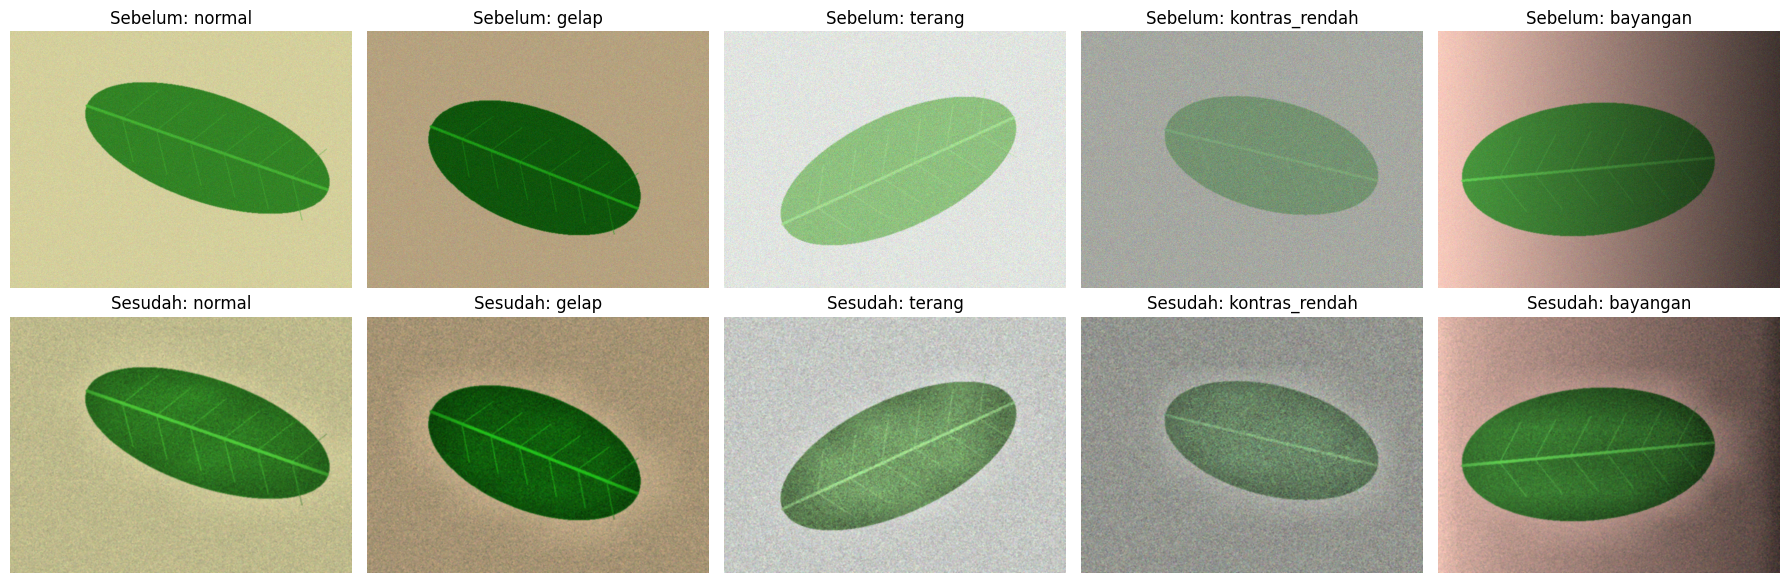

In [ ]:
import json
import matplotlib.pyplot as plt
from utils_cv import tampil

with open("../hasil/param_praproses.json") as f:
    param = json.load(f)
KANAL = 2  # sama dengan Tabel 12

sehat = label[label.kelas == "sehat"]

def mask_daun_erosi(path, ukuran):
    md = cv2.imread(path, 0)
    if md.shape != ukuran:
        md = cv2.resize(md, (ukuran[1], ukuran[0]), interpolation=cv2.INTER_NEAREST)
    return cv2.erode(md, np.ones((15, 15), np.uint8)) > 0

def titik_terang(k, daun, selisih=30, luas_min=5):
    k = k.astype(np.float32)
    hp = k - cv2.GaussianBlur(k, (0, 0), 15)
    biner = ((hp > selisih) & daun).astype(np.uint8)
    n, _, stat, _ = cv2.connectedComponentsWithStats(biner)
    return int((stat[1:, cv2.CC_STAT_AREA] >= luas_min).sum())

baris = []
for _, d in sehat.iterrows():
    img = baca(f"../data/sintetis/citra/{d.nama_file}")
    out = praproses(img, param)
    daun0 = mask_daun_erosi(f"../data/sintetis/mask_daun/{d.nama_file}", img.shape[:2])
    daun1 = mask_daun_erosi(f"../data/sintetis/mask_daun/{d.nama_file}", out.shape[:2])
    k0, k1 = img[:, :, KANAL], out[:, :, KANAL]
    baris.append([d.nama_file, d.kondisi_cahaya, k0[daun0].std(), k1[daun1].std(),
                  titik_terang(k0, daun0), titik_terang(k1, daun1)])

uji = pd.DataFrame(baris, columns=["nama", "kondisi", "std_sebelum", "std_sesudah",
                                   "titik_sebelum", "titik_sesudah"])
rekap = uji.groupby("kondisi")[["std_sebelum", "std_sesudah", "titik_sebelum", "titik_sesudah"]].mean()
rekap["rasio_std"] = rekap.std_sesudah / rekap.std_sebelum
print(rekap.round(2))
rekap.round(2).to_csv("../hasil/b5_uji_bercak_palsu.csv")

contoh = {"normal": "teh_001.png", "gelap": "teh_002.png", "terang": "teh_003.png",
          "kontras_rendah": "teh_004.png", "bayangan": "teh_005.png"}
sebelum, sesudah = [], []
for nm in contoh.values():
    im = baca(f"../data/sintetis/citra/{nm}")
    sebelum.append(im); sesudah.append(praproses(im, param))
tampil(sebelum + sesudah,
       [f"Sebelum: {k}" for k in contoh] + [f"Sesudah: {k}" for k in contoh],
       baris=2, ukuran=(18, 6))
plt.savefig("../hasil/b5_panel_sehat.png", dpi=150)

KB tanpa praproses (rata 40 citra): 6.54 | titik terang sebelum praproses (rata sehat): 2.10

=== RINGKASAN PER VARIASI ===
                    KB_rata_40  KB_ringan  KB_terang  KB_kontras_rendah  \
variasi                                                                   
A_dasar (clip2,k3)        8.43       6.61       5.86               4.77   
B_clip1,k3                9.85       8.04       8.25               6.68   
C_clip2,k5                9.19       6.97       6.25               5.39   
D_clip1,k5               10.78       8.55       8.92               7.81   
E_clip1.5,k3              9.04       7.20       6.81               5.53   
F_tanpa CLAHE,k3         10.63       9.09      10.36               8.14   

                    rasio_std_rata  titik_rata_sehat  titik_maks_kondisi  
variasi                                                                   
A_dasar (clip2,k3)            0.91              9.10               13.00  
B_clip1,k3                    0.68              9.

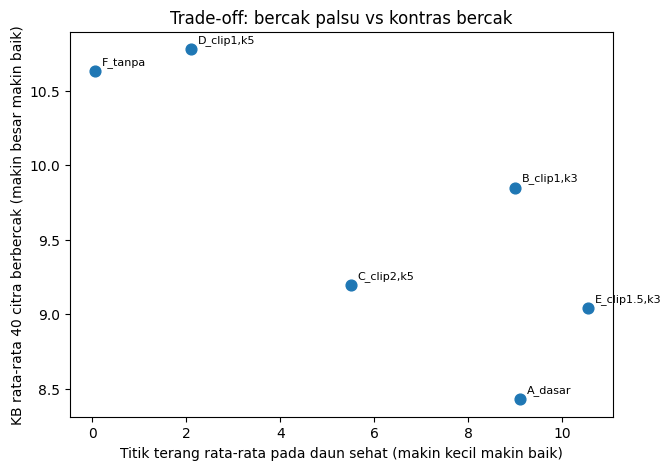

In [ ]:
import json, time
import numpy as np, cv2, pandas as pd
from utils_cv import baca, kontras_bercak
from praproses import praproses

KANAL = 2  # sama dengan Tabel 12 (0=B, 1=G, 2=R)
label = pd.read_csv("../data/sintetis/label.csv")

# ---------- variasi parameter yang diuji ----------
VARIASI = {
    "A_dasar (clip2,k3)":   {"gamma": 1.0, "clahe_clip": 2.0, "penapis": "median", "kernel": 3},
    "B_clip1,k3":           {"gamma": 1.0, "clahe_clip": 1.0, "penapis": "median", "kernel": 3},
    "C_clip2,k5":           {"gamma": 1.0, "clahe_clip": 2.0, "penapis": "median", "kernel": 5},
    "D_clip1,k5":           {"gamma": 1.0, "clahe_clip": 1.0, "penapis": "median", "kernel": 5},
    "E_clip1.5,k3":         {"gamma": 1.0, "clahe_clip": 1.5, "penapis": "median", "kernel": 3},
    "F_tanpa CLAHE,k3":     {"gamma": 1.0, "clahe_clip": 0.0, "penapis": "median", "kernel": 3},
}

# ---------- fungsi bantu (sama dengan Kode 5.3) ----------
def mask_daun_erosi(md, ukuran):
    if md.shape != ukuran:
        md = cv2.resize(md, (ukuran[1], ukuran[0]), interpolation=cv2.INTER_NEAREST)
    return cv2.erode(md, np.ones((15, 15), np.uint8)) > 0

def titik_terang(k, daun, selisih=30, luas_min=5):
    k = k.astype(np.float32)
    hp = k - cv2.GaussianBlur(k, (0, 0), 15)
    biner = ((hp > selisih) & daun).astype(np.uint8)
    n, _, stat, _ = cv2.connectedComponentsWithStats(biner)
    return int((stat[1:, cv2.CC_STAT_AREA] >= luas_min).sum())

# ---------- muat data sekali saja (hemat waktu) ----------
def muat(d):
    return (baca(f"../data/sintetis/citra/{d.nama_file}"),
            cv2.imread(f"../data/sintetis/mask_daun/{d.nama_file}", 0),
            cv2.imread(f"../data/sintetis/mask_bercak/{d.nama_file}", 0))

data_bercak = [(d, *muat(d)) for _, d in label[label.kelas != "sehat"].iterrows()]
data_sehat  = [(d, *muat(d)) for _, d in label[label.kelas == "sehat"].iterrows()]

# ---------- jalankan semua variasi ----------
rek_kb, rek_sehat, ringkas = [], [], []
for nama_v, p in VARIASI.items():
    # (1) KB pada 40 citra berbercak
    kb_rows = []
    for d, img, md, mb in data_bercak:
        out = praproses(img, p)
        kb_rows.append([nama_v, d.kelas, d.kondisi_cahaya,
                        kontras_bercak(img[:, :, KANAL], md, mb),
                        kontras_bercak(out[:, :, KANAL], md, mb)])
    kb = pd.DataFrame(kb_rows, columns=["variasi", "kelas", "kondisi", "KB_sblm", "KB_ssdh"])

    # (2) bercak palsu pada 20 citra sehat
    sh_rows = []
    for d, img, md, mb in data_sehat:
        out = praproses(img, p)
        d0 = mask_daun_erosi(md, img.shape[:2]); d1 = mask_daun_erosi(md, out.shape[:2])
        k0, k1 = img[:, :, KANAL], out[:, :, KANAL]
        sh_rows.append([nama_v, d.kondisi_cahaya, k0[d0].std(), k1[d1].std(),
                        titik_terang(k0, d0), titik_terang(k1, d1)])
    sh = pd.DataFrame(sh_rows, columns=["variasi", "kondisi", "std_sblm", "std_ssdh",
                                        "titik_sblm", "titik_ssdh"])
    rek_kb.append(kb); rek_sehat.append(sh)

    ringkas.append({
        "variasi": nama_v,
        "KB_rata_40": kb.KB_ssdh.mean(),
        "KB_ringan": kb[kb.kelas == "ringan"].KB_ssdh.mean(),   # indikator bercak kecil
        "KB_terang": kb[kb.kondisi == "terang"].KB_ssdh.mean(),
        "KB_kontras_rendah": kb[kb.kondisi == "kontras_rendah"].KB_ssdh.mean(),
        "rasio_std_rata": (sh.std_ssdh / sh.std_sblm).mean(),
        "titik_rata_sehat": sh.titik_ssdh.mean(),
        "titik_maks_kondisi": sh.groupby("kondisi").titik_ssdh.mean().max(),
    })

kb_all = pd.concat(rek_kb); sehat_all = pd.concat(rek_sehat)
ringkas = pd.DataFrame(ringkas).set_index("variasi")

# acuan: KB asli tanpa praproses dan titik sebelum praproses
kb_asli = kb_all[kb_all.variasi == VARIASI and False] if False else None
print("KB tanpa praproses (rata 40 citra): %.2f | titik terang sebelum praproses (rata sehat): %.2f"
      % (kb_all.KB_sblm.mean() / len(VARIASI) * len(VARIASI), sehat_all.titik_sblm.mean()))
print("\n=== RINGKASAN PER VARIASI ===")
print(ringkas.round(2))

# perubahan relatif terhadap variasi A (dasar)
dasar = ringkas.iloc[0]
rel = pd.DataFrame({
    "dKB_rata_%": 100 * (ringkas.KB_rata_40 - dasar.KB_rata_40) / dasar.KB_rata_40,
    "dKB_ringan_%": 100 * (ringkas.KB_ringan - dasar.KB_ringan) / dasar.KB_ringan,
    "dTitik_%": 100 * (ringkas.titik_rata_sehat - dasar.titik_rata_sehat) / max(dasar.titik_rata_sehat, 1e-6),
})
print("\n=== PERUBAHAN TERHADAP VARIASI A (dasar) ===")
print(rel.round(1))

# detail per kondisi (untuk Tabel 12 dan 5.3 versi final)
print("\n=== KB sesudah per kondisi ===")
print(kb_all.pivot_table(index="kondisi", columns="variasi", values="KB_ssdh").round(2))
print("\n=== Titik terang sesudah per kondisi (sehat) ===")
print(sehat_all.pivot_table(index="kondisi", columns="variasi", values="titik_ssdh").round(2))

ringkas.round(3).to_csv("../hasil/b5_uji_mitigasi_ringkas.csv")
kb_all.to_csv("../hasil/b5_uji_mitigasi_kb.csv", index=False)
sehat_all.to_csv("../hasil/b5_uji_mitigasi_sehat.csv", index=False)

# ---------- grafik: trade-off KB vs titik terang ----------
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(ringkas.titik_rata_sehat, ringkas.KB_rata_40, s=60)
for n, r in ringkas.iterrows():
    ax.annotate(n.split(" ")[0], (r.titik_rata_sehat, r.KB_rata_40),
                textcoords="offset points", xytext=(5, 5), fontsize=8)
ax.set_xlabel("Titik terang rata-rata pada daun sehat (makin kecil makin baik)")
ax.set_ylabel("KB rata-rata 40 citra berbercak (makin besar makin baik)")
ax.set_title("Trade-off: bercak palsu vs kontras bercak")
plt.savefig("../hasil/b5_tradeoff_mitigasi.png", dpi=150, bbox_inches="tight")
plt.show()

In [ ]:
import cv2, numpy as np, pandas as pd
from utils_cv import baca, kontras_bercak
from praproses import praproses, simpan_param

param = {"gamma": 1.0, "clahe_clip": 1.0, "clahe_tile": 8,
         "penapis": "median", "kernel": 5, "sigma": 1.0, "tajam_k": 0.0}
simpan_param(param, "../hasil/param_praproses.json")

KANAL = 2  # R, sama dengan sebelumnya (0=B, 1=G, 2=R)

label = pd.read_csv("../data/sintetis/label.csv")
baris = []
for _, d in label[label.kelas != "sehat"].iterrows():
    img = baca(f"../data/sintetis/citra/{d.nama_file}")
    md = cv2.imread(f"../data/sintetis/mask_daun/{d.nama_file}", 0)
    mb = cv2.imread(f"../data/sintetis/mask_bercak/{d.nama_file}", 0)
    out = praproses(img, param)
    baris.append([d.kondisi_cahaya,
                  kontras_bercak(img[:, :, KANAL], md, mb),
                  kontras_bercak(out[:, :, KANAL], md, mb)])

evaluasi = pd.DataFrame(baris, columns=["kondisi", "KB_sebelum", "KB_sesudah"])
tabel12 = evaluasi.groupby("kondisi").mean()
tabel12["perubahan_%"] = 100 * (tabel12.KB_sesudah - tabel12.KB_sebelum) / tabel12.KB_sebelum
print(tabel12.round(2))
tabel12.round(2).to_csv("../hasil/b5_tabel12_final.csv")

                KB_sebelum  KB_sesudah  perubahan_%
kondisi                                            
bayangan              5.00        7.82        56.46
gelap                 8.87       17.25        94.42
kontras_rendah        3.92        7.81        99.36
normal                8.89       12.09        35.97
terang                6.02        8.92        48.09


In [ ]:
def dI(k, md, mb):
    k = k.astype(float)
    sehat = (md > 0) & (mb == 0)
    return abs(k[mb > 0].mean() - k[sehat].mean())

hasil = {}
for nama_v in ["A_dasar (clip2,k3)", "D_clip1,k5", "F_tanpa CLAHE,k3"]:
    p = VARIASI[nama_v]
    vals = []
    for d, img, md, mb in data_bercak:
        if d.kelas != "ringan":
            continue
        out = praproses(img, p)
        vals.append([dI(img[:, :, KANAL], md, mb), dI(out[:, :, KANAL], md, mb)])
    hasil[nama_v] = np.mean(vals, axis=0)
print(pd.DataFrame(hasil, index=["dI_sebelum", "dI_sesudah"]).round(2))

            A_dasar (clip2,k3)  D_clip1,k5  F_tanpa CLAHE,k3
dI_sebelum               62.26       62.26             62.26
dI_sesudah               63.42       56.94             59.99


                std_sebelum  std_sesudah  titik_sebelum  titik_sesudah  \
kondisi                                                                  
bayangan              12.43         8.06           0.25           0.25   
gelap                  8.45         3.74           0.00           0.00   
kontras_rendah        10.44         4.81           0.00           0.00   
normal                 9.28         6.03           3.00           7.25   
terang                11.94         7.79           7.25           3.00   

                rasio_std  
kondisi                    
bayangan             0.65  
gelap                0.44  
kontras_rendah       0.46  
normal               0.65  
terang               0.65  


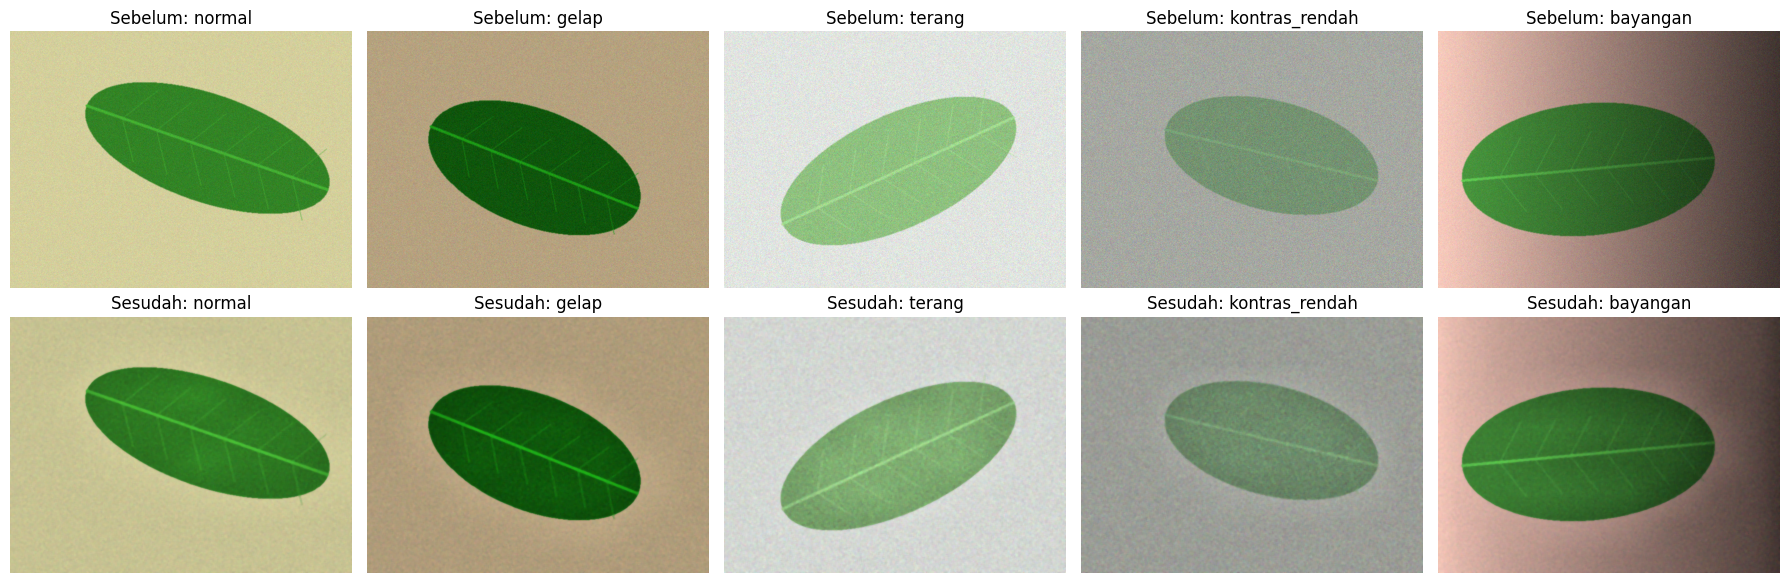

In [ ]:
import matplotlib.pyplot as plt
from utils_cv import tampil

sehat = label[label.kelas == "sehat"]

def mask_daun_erosi(path, ukuran):
    md = cv2.imread(path, 0)
    if md.shape != ukuran:
        md = cv2.resize(md, (ukuran[1], ukuran[0]), interpolation=cv2.INTER_NEAREST)
    return cv2.erode(md, np.ones((15, 15), np.uint8)) > 0

def titik_terang(k, daun, selisih=30, luas_min=5):
    k = k.astype(np.float32)
    hp = k - cv2.GaussianBlur(k, (0, 0), 15)
    biner = ((hp > selisih) & daun).astype(np.uint8)
    n, _, stat, _ = cv2.connectedComponentsWithStats(biner)
    return int((stat[1:, cv2.CC_STAT_AREA] >= luas_min).sum())

baris = []
for _, d in sehat.iterrows():
    img = baca(f"../data/sintetis/citra/{d.nama_file}")
    out = praproses(img, param)
    daun0 = mask_daun_erosi(f"../data/sintetis/mask_daun/{d.nama_file}", img.shape[:2])
    daun1 = mask_daun_erosi(f"../data/sintetis/mask_daun/{d.nama_file}", out.shape[:2])
    k0, k1 = img[:, :, KANAL], out[:, :, KANAL]
    baris.append([d.nama_file, d.kondisi_cahaya, k0[daun0].std(), k1[daun1].std(),
                  titik_terang(k0, daun0), titik_terang(k1, daun1)])

uji = pd.DataFrame(baris, columns=["nama", "kondisi", "std_sebelum", "std_sesudah",
                                   "titik_sebelum", "titik_sesudah"])
rekap = uji.groupby("kondisi")[["std_sebelum", "std_sesudah",
                                "titik_sebelum", "titik_sesudah"]].mean()
rekap["rasio_std"] = rekap.std_sesudah / rekap.std_sebelum
print(rekap.round(2))
rekap.round(2).to_csv("../hasil/b5_uji_bercak_palsu_final.csv")

# panel sebelum & sesudah: 1 citra sehat per kondisi
contoh = {"normal": "teh_001.png", "gelap": "teh_002.png", "terang": "teh_003.png",
          "kontras_rendah": "teh_004.png", "bayangan": "teh_005.png"}
sebelum, sesudah = [], []
for nm in contoh.values():
    im = baca(f"../data/sintetis/citra/{nm}")
    sebelum.append(im); sesudah.append(praproses(im, param))
tampil(sebelum + sesudah,
       [f"Sebelum: {k}" for k in contoh] + [f"Sesudah: {k}" for k in contoh],
       baris=2, ukuran=(18, 6))
plt.savefig("../hasil/b5_panel_sehat_final.png", dpi=150)
plt.show()

In [ ]:
param_final = {"gamma": 1.0, "clahe_clip": 1.0, "clahe_tile": 8,
               "penapis": "median", "kernel": 5, "sigma": 1.0, "tajam_k": 0.0}
simpan_param(param_final, "../hasil/param_praproses.json")

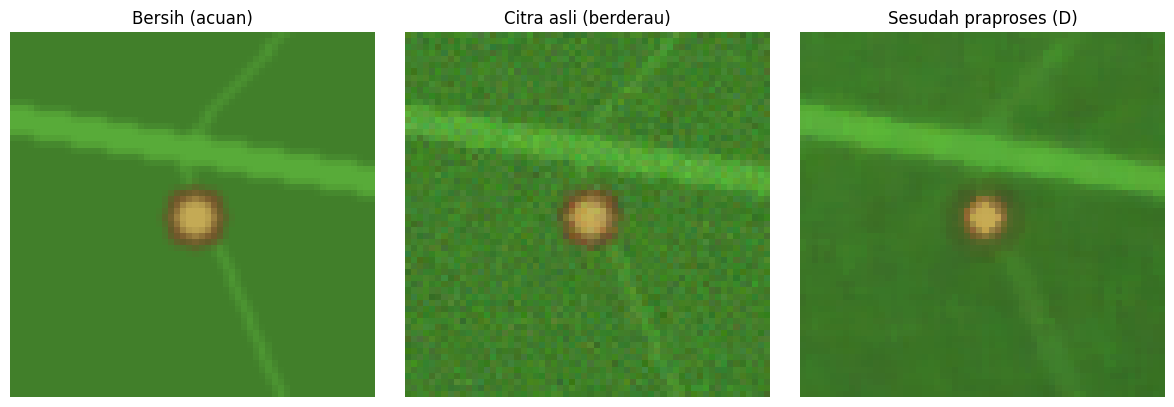

Bersih (acuan)            rerata R pada bercak = 135.9
Citra asli (berderau)     rerata R pada bercak = 136.2
Sesudah praproses (D)     rerata R pada bercak = 116.7
luas bercak terbesar (px): 81 | diameter kira-kira: 10.2 px


In [ ]:
import cv2, numpy as np, matplotlib.pyplot as plt
from utils_cv import baca

nama = "teh_021.png"   # ringan, kondisi normal (boleh ganti, mis. teh_022 untuk gelap)
img   = baca(f"../data/sintetis/citra/{nama}")
bersih = baca(f"../data/sintetis/bersih/{nama}")
mb    = cv2.imread(f"../data/sintetis/mask_bercak/{nama}", 0)
out   = praproses(img, param)          # param = parameter D (lebar 640 => ukuran sama)

# pilih bercak terbesar dari mask acuan
n, lab, stat, cen = cv2.connectedComponentsWithStats((mb > 0).astype(np.uint8))
i = 1 + np.argmax(stat[1:, cv2.CC_STAT_AREA])
cx, cy = map(int, cen[i])
r = 30                                  # setengah lebar crop (piksel)
y0, y1 = max(cy - r, 0), cy + r
x0, x1 = max(cx - r, 0), cx + r

def potong(a): return a[y0:y1, x0:x1]
judul = ["Bersih (acuan)", "Citra asli (berderau)", "Sesudah praproses (D)"]
panel = [potong(bersih), potong(img), potong(out)]

plt.figure(figsize=(12, 4))
for k, (im, jd) in enumerate(zip(panel, judul)):
    plt.subplot(1, 3, k + 1)
    plt.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB), interpolation="nearest")
    plt.title(jd); plt.axis("off")
plt.tight_layout()
plt.savefig("../hasil/b5_crop_bercak.png", dpi=150)
plt.show()

# angka pendukung: luas bercak terbesar dan kontras lokalnya (kanal R)
luas = stat[i, cv2.CC_STAT_AREA]
for jd, im in zip(judul, [bersih, img, out]):
    k = im[:, :, KANAL].astype(float)
    pusat = k[mb > 0][: ].mean()
    print(f"{jd:25s} rerata R pada bercak = {pusat:.1f}")
print("luas bercak terbesar (px):", luas, "| diameter kira-kira:", round(2*np.sqrt(luas/np.pi), 1), "px")

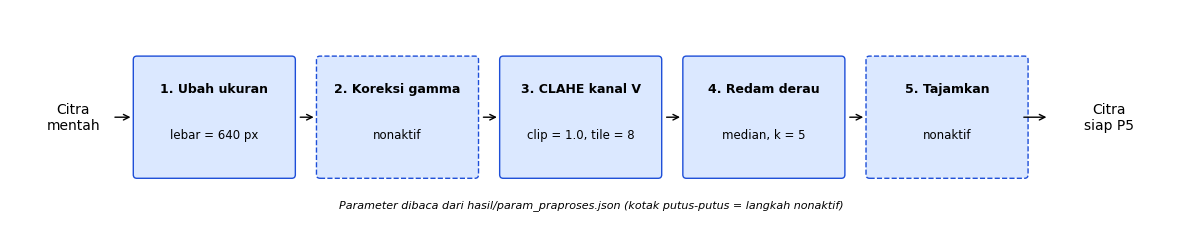

In [ ]:
import json
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

p = json.load(open("../hasil/param_praproses.json"))

langkah = [
    ("1. Ubah ukuran",   f"lebar = {p['lebar']} px"),
    ("2. Koreksi gamma", "nonaktif" if p["gamma"] == 1 else f"gamma = {p['gamma']}"),
    ("3. CLAHE kanal V", f"clip = {p['clahe_clip']}, tile = {p['clahe_tile']}"),
    ("4. Redam derau",   f"{p['penapis']}, k = {p['kernel']}"),
    ("5. Tajamkan",      "nonaktif" if p["tajam_k"] == 0 else f"k = {p['tajam_k']}"),
]

fig, ax = plt.subplots(figsize=(15, 2.8))
ax.axis("off"); ax.set_xlim(0, 16.5); ax.set_ylim(0, 3)

# label awal dan panah ke kotak 1
ax.text(0.9, 1.5, "Citra\nmentah", va="center", ha="center", fontsize=10)
ax.annotate("", xy=(1.75, 1.5), xytext=(1.45, 1.5), arrowprops=dict(arrowstyle="->"))

# lima kotak langkah
for i, (judul, par) in enumerate(langkah):
    x = 1.8 + i * 2.6
    ls = "--" if "nonaktif" in par else "-"      # langkah nonaktif: putus-putus
    ax.add_patch(FancyBboxPatch((x, 0.7), 2.2, 1.6, boxstyle="round,pad=0.05",
                                fc="#dbe8ff", ec="#1d4ed8", ls=ls))
    ax.text(x + 1.1, 1.85, judul, ha="center", fontsize=9, weight="bold")
    ax.text(x + 1.1, 1.2, par, ha="center", fontsize=8.5)
    if i < len(langkah) - 1:
        ax.annotate("", xy=(x + 2.55, 1.5), xytext=(x + 2.28, 1.5),
                    arrowprops=dict(arrowstyle="->"))

# panah dan label akhir (digeser supaya tidak menimpa kotak 5)
ax.annotate("", xy=(14.75, 1.5), xytext=(14.35, 1.5), arrowprops=dict(arrowstyle="->"))
ax.text(15.6, 1.5, "Citra\nsiap P5", va="center", ha="center", fontsize=10)

# catatan bawah
ax.text(8.25, 0.25, "Parameter dibaca dari hasil/param_praproses.json "
        "(kotak putus-putus = langkah nonaktif)", ha="center", fontsize=8, style="italic")

plt.savefig("../hasil/b5_pipeline_final.png", dpi=150, bbox_inches="tight")
plt.show()